In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings

from PIL import Image, ImageEnhance
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import joblib

# Data paths
IMAGES_PATH = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images"
MASKS_PATH  = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images"
CARDIO_PATH = "/kaggle/input/datasets/sulianova/cardiovascular-disease-dataset/cardio_train.csv"
OUTPUT_DIR  = "/kaggle/working/"

IMG_SIZE = 256  # Target resize dimension for all images

images_list = sorted(os.listdir(IMAGES_PATH))
masks_list  = sorted(os.listdir(MASKS_PATH))

print(f"Images: {len(images_list)} | Masks: {len(masks_list)}")
print(f"IMG_SIZE set to: {IMG_SIZE}x{IMG_SIZE} px")

Images: 1100 | Masks: 1100
IMG_SIZE set to: 256x256 px


In [14]:
def preprocess_image(img_path, size=IMG_SIZE):
    """
    Load image, resize, and normalize.
    Returns float32 numpy array in range [0, 1].
    """
    img = Image.open(img_path).convert('L')           # Grayscale
    img = img.resize((size, size), Image.LANCZOS)     # Resize
    arr = np.array(img, dtype=np.float32) / 255.0     # Normalize to [0, 1]
    return arr

def preprocess_mask(mask_path, size=IMG_SIZE):
    """
    Load mask, resize, and binarize.
    Returns float32 numpy array: 0 = background, 1 = artery.
    """
    mask = Image.open(mask_path).convert('L')
    mask = mask.resize((size, size), Image.NEAREST)   # NEAREST preserves binary values
    arr  = np.array(mask, dtype=np.float32) / 255.0
    arr  = (arr > 0.5).astype(np.float32)             # Strict binarization
    return arr

# Load all images and masks
print("Loading images... (may take 1–2 minutes)")

all_images = []
all_masks  = []

for i, (img_name, mask_name) in enumerate(zip(images_list, masks_list)):
    img  = preprocess_image(os.path.join(IMAGES_PATH, img_name))
    mask = preprocess_mask(os.path.join(MASKS_PATH,  mask_name))
    all_images.append(img)
    all_masks.append(mask)

    if (i + 1) % 100 == 0:
        print(f"  Processed: {i + 1}/{len(images_list)}")

all_images = np.array(all_images)  # Shape: (N, 256, 256)
all_masks  = np.array(all_masks)   # Shape: (N, 256, 256)

print(f"\n✅ Images shape: {all_images.shape}")
print(f"✅ Masks shape:   {all_masks.shape}")
print(f"✅ Images range — min: {all_images.min():.2f}, max: {all_images.max():.2f}")
print(f"✅ Masks values — unique: {np.unique(all_masks)}")

Loading images... (may take 1–2 minutes)
  Processed: 100/1100
  Processed: 200/1100
  Processed: 300/1100
  Processed: 400/1100
  Processed: 500/1100
  Processed: 600/1100
  Processed: 700/1100
  Processed: 800/1100
  Processed: 900/1100
  Processed: 1000/1100
  Processed: 1100/1100

✅ Images shape: (1100, 256, 256)
✅ Masks shape:   (1100, 256, 256)
✅ Images range — min: 0.00, max: 1.00
✅ Masks values — unique: [0. 1.]


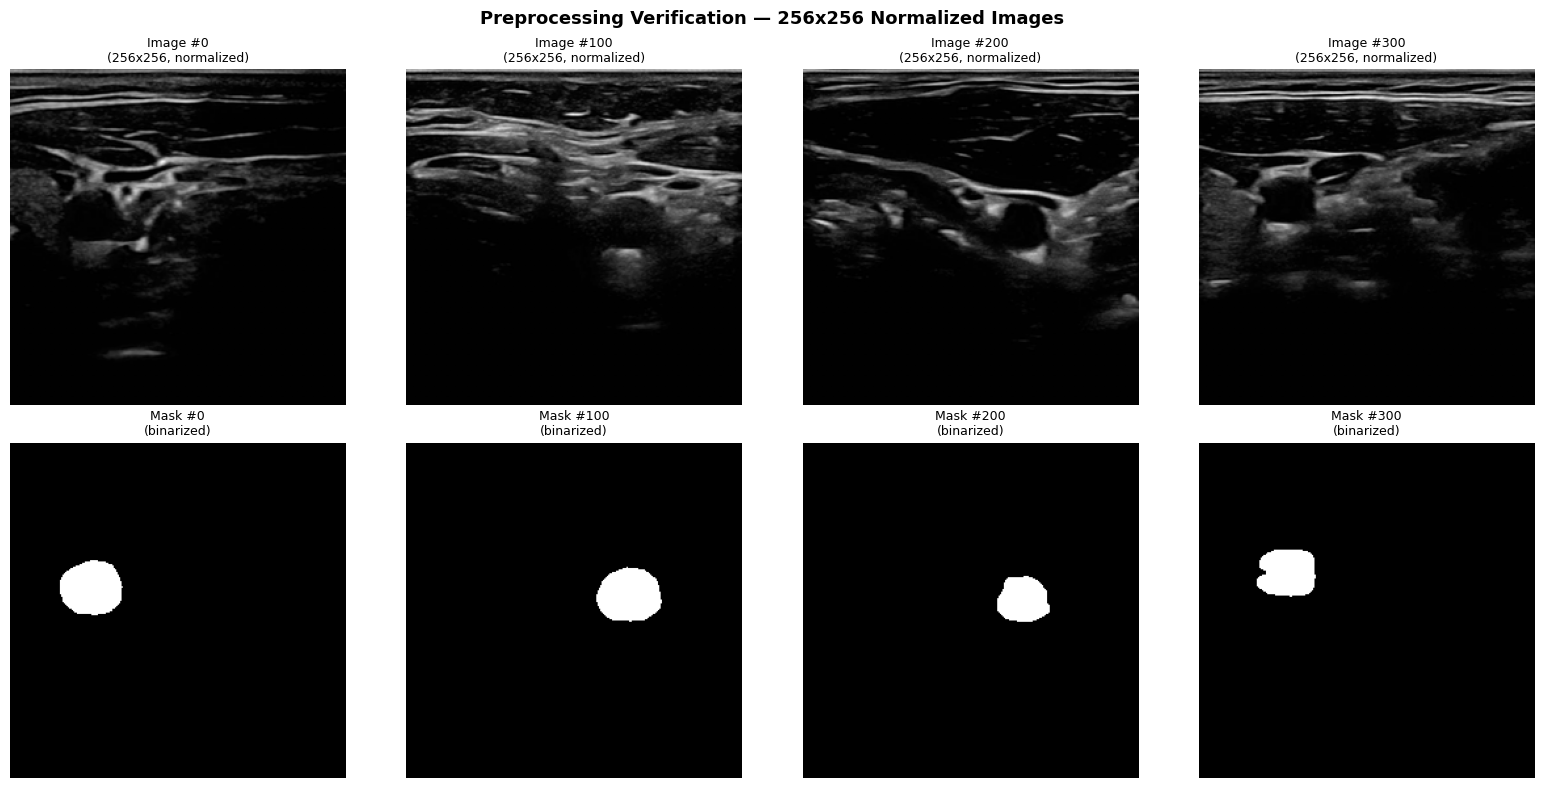

✅ Visual verification OK!


In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Preprocessing Verification — 256x256 Normalized Images', 
             fontsize=13, fontweight='bold')

for i in range(4):
    axes[0, i].imshow(all_images[i * 100], cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f'Image #{i * 100}\n(256x256, normalized)', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(all_masks[i * 100], cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title(f'Mask #{i * 100}\n(binarized)', fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'preprocessing_verification.png'), dpi=150)
plt.show()
print("✅ Visual verification OK!")

In [16]:
def augment_image_mask(image, mask):
    """
    Apply identical augmentations to both image and mask.
    Augmentations are IDENTICAL on both — mask must align with image!
    """
    augmented_images = [image]
    augmented_masks  = [mask]

    # 1. Horizontal flip
    aug_img  = np.fliplr(image)
    aug_mask = np.fliplr(mask)
    augmented_images.append(aug_img)
    augmented_masks.append(aug_mask)

    # 2. Vertical flip
    aug_img  = np.flipud(image)
    aug_mask = np.flipud(mask)
    augmented_images.append(aug_img)
    augmented_masks.append(aug_mask)

    # 3. Brightness variation (image only, not mask)
    pil_img = Image.fromarray((image * 255).astype(np.uint8))
    bright  = ImageEnhance.Brightness(pil_img).enhance(1.3)
    augmented_images.append(np.array(bright, dtype=np.float32) / 255.0)
    augmented_masks.append(mask)

    return augmented_images, augmented_masks

# Apply augmentation to all images
print("Applying data augmentation...")

aug_images, aug_masks = [], []
for i, (img, mask) in enumerate(zip(all_images, all_masks)):
    imgs, msks = augment_image_mask(img, mask)
    aug_images.extend(imgs)
    aug_masks.extend(msks)
    if (i + 1) % 200 == 0:
        print(f"  Augmented: {i + 1}/{len(all_images)}")

aug_images = np.array(aug_images)
aug_masks  = np.array(aug_masks)

print(f"\n✅ Before augmentation: {len(all_images)} images")
print(f"✅ After augmentation:  {len(aug_images)} images (x4)")

Applying data augmentation...
  Augmented: 200/1100
  Augmented: 400/1100
  Augmented: 600/1100
  Augmented: 800/1100
  Augmented: 1000/1100

✅ Before augmentation: 1100 images
✅ After augmentation:  4400 images (x4)


✅ Split completed:
   Train : 3080 images (70.0%)
   Val   : 660   images (15.0%)
   Test  : 660  images (15.0%)


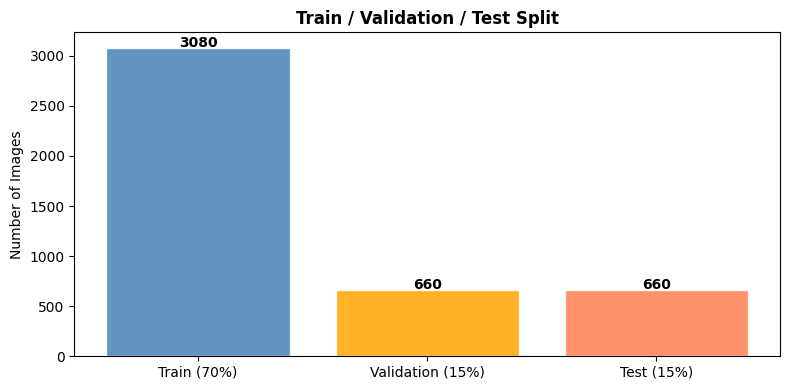

In [17]:
# Stratified split 70 / 15 / 15
indices = np.arange(len(aug_images))

# First: 70% train, 30% temp
idx_train, idx_temp = train_test_split(
    indices, test_size=0.30, random_state=42
)

# Then: 30% temp → 15% val + 15% test
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, random_state=42
)

X_train = aug_images[idx_train]
X_val   = aug_images[idx_val]
X_test  = aug_images[idx_test]

y_train = aug_masks[idx_train]
y_val   = aug_masks[idx_val]
y_test  = aug_masks[idx_test]

print("✅ Split completed:")
print(f"   Train : {len(X_train)} images ({len(X_train)/len(aug_images)*100:.1f}%)")
print(f"   Val   : {len(X_val)}   images ({len(X_val)/len(aug_images)*100:.1f}%)")
print(f"   Test  : {len(X_test)}  images ({len(X_test)/len(aug_images)*100:.1f}%)")

# Visualize split
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['Train (70%)', 'Validation (15%)', 'Test (15%)'],
              [len(X_train), len(X_val), len(X_test)],
              color=['steelblue', 'orange', 'coral'], edgecolor='white', alpha=0.85)
for bar, val in zip(bars, [len(X_train), len(X_val), len(X_test)]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            str(val), ha='center', fontweight='bold')
ax.set_title('Train / Validation / Test Split', fontweight='bold')
ax.set_ylabel('Number of Images')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'split_chart.png'), dpi=150)
plt.show()

In [18]:
df = pd.read_csv(CARDIO_PATH, sep=';')

# ── Outlier cleaning ──────────────────────────────────────────
df = df[(df['ap_hi'] >= 80)  & (df['ap_hi'] <= 240)]
df = df[(df['ap_lo'] >= 40)  & (df['ap_lo'] <= 150)]
df = df[(df['height'] >= 140) & (df['height'] <= 210)]
df = df[(df['weight'] >= 40)  & (df['weight'] <= 180)]
df = df[df['ap_hi'] > df['ap_lo']]  # Systolic > diastolic

print(f"✅ After cleaning: {len(df)} patients (out of {len(pd.read_csv(CARDIO_PATH, sep=';'))})")

# ── Feature Engineering ───────────────────────────────────────
df['age_years']      = (df['age'] / 365).astype(int)
df['bmi']            = (df['weight'] / (df['height'] / 100) ** 2).round(1)
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']  # Pulse pressure

# Generate clinical text per patient (for TF-IDF)
def generate_risk_text(row):
    """
    Convert patient's numeric features into descriptive text.
    This will be vectorized with TF-IDF.
    """
    tokens = []

    # Age
    if row['age_years'] > 65:   tokens.append('elderly')
    elif row['age_years'] > 50: tokens.append('middle_aged')
    else:                        tokens.append('young')

    # Blood pressure
    if row['ap_hi'] > 160:      tokens.append('hypertensive_grade2')
    elif row['ap_hi'] > 140:    tokens.append('hypertensive_grade1')
    else:                        tokens.append('normotensive')

    # BMI
    if row['bmi'] > 30:         tokens.append('obese')
    elif row['bmi'] > 25:       tokens.append('overweight')
    else:                        tokens.append('normal_weight')

    # Cholesterol
    if row['cholesterol'] == 3: tokens.append('high_cholesterol')
    elif row['cholesterol'] == 2: tokens.append('moderate_cholesterol')
    else:                         tokens.append('normal_cholesterol')

    # Glucose
    if row['gluc'] == 3:        tokens.append('high_glucose')
    elif row['gluc'] == 2:      tokens.append('moderate_glucose')

    # Behavioral factors
    if row['smoke']:             tokens.append('smoker')
    if row['alco']:              tokens.append('alcohol_consumer')
    if not row['active']:        tokens.append('sedentary')

    # Pulse pressure
    if row['pulse_pressure'] > 60: tokens.append('high_pulse_pressure')

    return ' '.join(tokens)

df['risk_text'] = df.apply(generate_risk_text, axis=1)

print("\n✅ Examples of generated risk_text:")
print(df[['age_years', 'ap_hi', 'bmi', 'risk_text', 'cardio']].head(5).to_string())

✅ After cleaning: 68467 patients (out of 70000)

✅ Examples of generated risk_text:
   age_years  ap_hi   bmi                                                          risk_text  cardio
0         50    110  22.0                young normotensive normal_weight normal_cholesterol       0
1         55    140  34.9                    middle_aged normotensive obese high_cholesterol       1
2         51    130  23.5  middle_aged normotensive normal_weight high_cholesterol sedentary       1
3         48    150  28.7            young hypertensive_grade1 overweight normal_cholesterol       1
4         47    100  23.0      young normotensive normal_weight normal_cholesterol sedentary       0


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# Numeric, categorical, and text features
numeric_features   = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categorical_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']
text_feature       = 'risk_text'

# Split clinical data (stratified on target)
df_train, df_temp = train_test_split(df, test_size=0.30, random_state=42,
                                      stratify=df['cardio'])
df_val, df_test   = train_test_split(df_temp, test_size=0.50, random_state=42,
                                      stratify=df_temp['cardio'])

print(f"✅ Clinical data split:")
print(f"   Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# sklearn pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num',  StandardScaler(),                      numeric_features),
    ('cat',  OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

# Separate processing for text (TF-IDF)
tfidf = TfidfVectorizer(max_features=100, ngram_range=(1, 2))

# Fit on train, transform on val and test
X_train_tab = preprocessor.fit_transform(df_train[numeric_features + categorical_features])
X_val_tab   = preprocessor.transform(df_val[numeric_features + categorical_features])
X_test_tab  = preprocessor.transform(df_test[numeric_features + categorical_features])

X_train_tfidf = tfidf.fit_transform(df_train[text_feature])
X_val_tfidf   = tfidf.transform(df_val[text_feature])
X_test_tfidf  = tfidf.transform(df_test[text_feature])

# Concatenate tabular + TF-IDF features
X_train_clinical = hstack([X_train_tab, X_train_tfidf])
X_val_clinical   = hstack([X_val_tab,   X_val_tfidf])
X_test_clinical  = hstack([X_test_tab,  X_test_tfidf])

y_train_clinical = df_train['cardio'].values
y_val_clinical   = df_val['cardio'].values
y_test_clinical  = df_test['cardio'].values

print(f"\n✅ Clinical features shape (train): {X_train_clinical.shape}")
print(f"   (patients x combined tabular+tfidf features)")

✅ Clinical data split:
   Train: 47926 | Val: 10270 | Test: 10271

✅ Clinical features shape (train): (47926, 92)
   (patients x combined tabular+tfidf features)


In [20]:
# Save processed images
np.save(os.path.join(OUTPUT_DIR, 'X_train_img.npy'), X_train)
np.save(os.path.join(OUTPUT_DIR, 'X_val_img.npy'),   X_val)
np.save(os.path.join(OUTPUT_DIR, 'X_test_img.npy'),  X_test)
np.save(os.path.join(OUTPUT_DIR, 'y_train_img.npy'), y_train)
np.save(os.path.join(OUTPUT_DIR, 'y_val_img.npy'),   y_val)
np.save(os.path.join(OUTPUT_DIR, 'y_test_img.npy'),  y_test)

# Save processed clinical data
df_train.to_csv(os.path.join(OUTPUT_DIR, 'clinical_train.csv'), index=False)
df_val.to_csv(os.path.join(OUTPUT_DIR,   'clinical_val.csv'),   index=False)
df_test.to_csv(os.path.join(OUTPUT_DIR,  'clinical_test.csv'),  index=False)

# Save preprocessor and tfidf (needed for inference and Streamlit)
joblib.dump(preprocessor, os.path.join(OUTPUT_DIR, 'preprocessor.pkl'))
joblib.dump(tfidf,        os.path.join(OUTPUT_DIR, 'tfidf_vectorizer.pkl'))

print("✅ All data saved to Output!")
print("\n📁 Saved files:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024
    print(f"   {f} — {size:.1f} KB")

✅ All data saved to Output!

📁 Saved files:
   .virtual_documents — 4.0 KB
   X_test_img.npy — 168960.1 KB
   X_train_img.npy — 788480.1 KB
   X_val_img.npy — 168960.1 KB
   clinical_test.csv — 1142.2 KB
   clinical_train.csv — 5322.7 KB
   clinical_val.csv — 1139.0 KB
   preprocessing_verification.png — 423.0 KB
   preprocessor.pkl — 3.0 KB
   split_chart.png — 35.6 KB
   tfidf_vectorizer.pkl — 4.8 KB
   y_test_img.npy — 168960.1 KB
   y_train_img.npy — 788480.1 KB
   y_val_img.npy — 168960.1 KB
